# ПРАКТИЧЕСКОЕ ЗАДАНИЕ 3. ОБРАБОТКА ТЕКСТА 


В данной работе будут использоватся спаршенные в 1 практике новости


Первым шагом переведем данные из формата json в csv, отбросив все кроме полного текста статей.

In [17]:
import json
import csv

with open('news_text.json', 'r', encoding='utf-8') as file:
    old_data  = json.load(file)


texts = [record["full_text"] for record in old_data]


with open('raw_text.csv', 'w', encoding='utf-8-sig', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(["full_text"])
    for text in texts:
        text = text.replace("\n", " ")
        writer.writerow([text])

теперь у нас есть файл csv, который содержит только текста. Далее выполним токенезацию и очистку текста, а также леммаизацию.

In [28]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
import pandas as pd

# nltk.download('stopwords')
# nltk.download('punkt')
# nltk.download('punkt_tab')
# nltk.download('wordnet')
# nltk.download('omw-1.4')
# nltk.download('averaged_perceptron_tagger_eng')

STOP_WORDS = (set(stopwords.words('english')) - {"no", "nor", "not"}) | {"ca", "wo", "e"}
URL_RE = re.compile(r"https?://\S+|www\.\S+")


lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag: str):
    if tag.startswith('J'):
        return wordnet.ADJ
    if tag.startswith('V'):
        return wordnet.VERB
    if tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

def lemmatize_tokens(tokens):
    tagged = nltk.pos_tag(tokens)
    return [lemmatizer.lemmatize(tok, get_wordnet_pos(tag)) for tok, tag in tagged]

def tokenizer(text: str):
    text = text.lower()
    text = URL_RE.sub(" ", text)
    tokens = word_tokenize(text)
    tokens = ["not" if t == "n't" else t for t in tokens]  
    tokens = [t for t in tokens if t.isalpha()]
    tokens = lemmatize_tokens(tokens)
    tokens = [t for t in tokens if t not in STOP_WORDS]
    return tokens

df = pd.read_csv("raw_text.csv", encoding='utf-8-sig')


df["tokens"] = df["full_text"].apply(tokenizer)

        

In [29]:
from collections import Counter
import matplotlib.pyplot as plt

all_tokens = [t for toks in df["tokens"] for t in toks]
freq = Counter(all_tokens)

top20 = pd.DataFrame(freq.most_common(20), columns=["word", "count"])
top20.index += 1
display(top20)

,word,count
1,say,1975
2,not,1941
3,one,1059
4,year,993
5,make,977
6,also,890
7,new,882
8,time,768
9,get,731
10,like,702


[nltk_data] Error loading vader_lexicon: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


sentiment
positive    503
negative    119
neutral      28
Name: count, dtype: int64

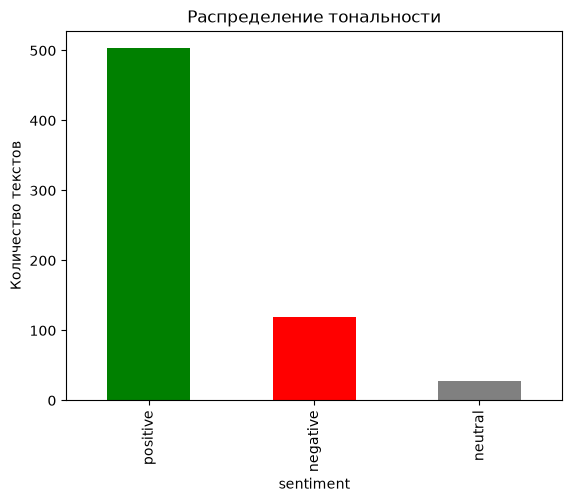

In [32]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    score = sia.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"

df["compound"] = df["full_text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment"] = df["compound"].apply(
    lambda s: "positive" if s >= 0.05 else ("negative" if s <= -0.55 else "neutral")
)

counts = df["sentiment"].value_counts()
display(counts)

counts.plot(kind="bar", color=["green", "red", "gray"], title="Распределение тональности")
plt.ylabel("Количество текстов")
plt.show()

In [21]:

sample = df.sample(50, random_state=42)[["full_text", "sentiment"]]
sample["manual"] = "" 
sample.to_csv("sample_for_labeling.csv", index=False)

В ручную читать долго, поэтому в данном полученном sample_for_labeling.csv разбиением занималась более соверешнная ИИ модель в частности claude

In [22]:
from sklearn.metrics import classification_report
sample = pd.read_csv("sample_for_labeling_labeled.csv")
print(classification_report(sample["manual"], sample["sentiment"]))

              precision    recall  f1-score   support

    negative       0.58      0.37      0.45        19
     neutral       0.00      0.00      0.00        13
    positive       0.43      0.89      0.58        18

    accuracy                           0.46        50
   macro avg       0.34      0.42      0.34        50
weighted avg       0.38      0.46      0.38        50



In [33]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm", disable=["lemmatizer"])

texts = df["full_text"].apply(lambda t: URL_RE.sub(" ", t)).tolist()

entities = []
for doc in nlp.pipe(texts, batch_size=200):
    entities.append([(ent.text, ent.label_) for ent in doc.ents])

df["entities"] = entities


all_ents = [e for ents in entities for e in ents]
label_counts = Counter(label for _, label in all_ents)
display(pd.DataFrame(label_counts.most_common(), columns=["label", "count"]))


for label in ["ORG", "PERSON", "CARDINAL", "DATE", "GPE"]:
    top = Counter(text for text, l in all_ents if l == label).most_common(10)
    print(f"\n=== {label} ===")
    display(pd.DataFrame(top, columns=["entity", "count"]))

,label,count
0,ORG,8786
1,PERSON,8231
2,CARDINAL,6393
3,DATE,6195
4,GPE,4653
5,MONEY,1371
6,NORP,1298
7,ORDINAL,911
8,TIME,625
9,WORK_OF_ART,545



=== ORG ===


,entity,count
0,Trump,156
1,Google,75
2,AI,73
3,Bills,68
4,Congress,55
5,Amazon,50
6,Apple,44
7,- Access News Break,42
8,Instagram,40
9,AP,36



=== PERSON ===


,entity,count
0,Trump,125
1,Harry,88
2,Donald Trump,63
3,Macklemore,48
4,Brandon Sun,42
5,Email Print Copy,41
6,Evo Slim,39
7,Kalshi,35
8,Gunn,34
9,Hegseth,31


...

,entity,count
0,one,420
1,two,366
2,E96,342
3,2,268
4,three,204
5,2?5,168
6,four,118
7,One,101
8,6,89
9,five,78



=== DATE ===


,entity,count
0,Tuesday,257
1,2026,198
2,today,146
3,annual,114
4,Monday,104
5,last year,67
6,2024,57
7,2025,53
8,years,43
9,2023,43



=== GPE ===


,entity,count
0,AI,263
1,U.S.,151
2,US,127
3,China,117
4,Sheeran,110
5,Canada,77
6,Australia,71
7,California,69
8,New York,64
9,the United States,61


In [35]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

docs = df["tokens"].apply(lambda toks: " ".join(toks))

vectorizer = CountVectorizer(max_df=0.5, min_df=5)
X = vectorizer.fit_transform(docs)

N_TOPICS = 6   # подберите под свои данные
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42)
doc_topics = lda.fit_transform(X)

# Топ-слова каждой темы
words = vectorizer.get_feature_names_out()
for i, comp in enumerate(lda.components_):
    top_words = [words[j] for j in comp.argsort()[-10:][::-1]]
    print(f"Тема {i}: {', '.join(top_words)}")

df["topic"] = doc_topics.argmax(axis=1)
display(df["topic"].value_counts())

Тема 0: week, first, play, season, go, game, read, digital, take, team
Тема 1: trump, state, court, would, county, president, election, vote, forest, case
Тема 2: energy, ai, company, market, could, project, would, solar, build, product
Тема 3: use, tool, agent, school, ai, google, run, model, harry, every
Тема 4: bill, de, buffalo, article, sep, ed, season, win, kam, bean
Тема 5: like, get, look, feel, people, best, come, go, work, no


topic
0    172
1    127
2    122
5    115
4     69
3     45
Name: count, dtype: int64

In [36]:
import numpy as np

df["topic_conf"] = doc_topics.max(axis=1)
for k in range(N_TOPICS):
    top_docs = df[df["topic"] == k].nlargest(3, "topic_conf")
    print(f"\n=== Тема {k} ===")
    for t in top_docs["full_text"]:
        print("-", " ".join(t.split())[:150])


=== Тема 0 ===
- Ole Miss players aren’t making much – at least publicly – of Lane Kiffin’s return with LSU Advertisement Read this article for free: or Already have a
- Paul George understands sentiments after trade, says he’s ready to prove himself with Celtics Advertisement Read this article for free: or Already hav
- Veteran receiver Damonte Coxie enjoying best CFL season with Toronto Argonauts Advertisement Read this article for free: or Already have an account? L

=== Тема 1 ===
- President Donald Trump’s plan to kneecap mail-voting practices in November’s midterms ran aground on Monday evening after the Supreme Court blocked th
- A rare Australian sea lion (Neophoca cinerea) on Kangaroo Island has been confirmed to have died from highly pathogenic H5N1 bird flu. The sea lion ha
- After the US supreme court halted Donald Trump’s efforts to make it significantly harder to vote by mail in the midterms, US election officials are re

=== Тема 2 ===
- NanoXplore (TSX:GRA) released fo